# EDA metrik tools supporting — run `data-v3-20261107`

`dataset.csv` hanya berisi telemetri **sidecar** (psutil, nvidia-smi) dan kolom `prom_*` dari
**cAdvisor + kube-state-metrics**. Metrik dari tools supporting lain (OpenTelemetry Collector,
Inspektor Gadget, NetObserv, Linkerd) **tidak ikut** di dalamnya; metrik itu hanya tersimpan di
Prometheus. Notebook ini menganalisis metrik supporting yang diekspor dari arsip Prometheus oleh
`fetch_supporting_metrics.py`.

| Tool supporting | Yang terekam selama run | Level | Tersedia di |
|---|---|---|---|
| **OpenTelemetry** kubeletstats | CPU, memori, page fault, filesystem, network per Pod/container | Pod sesi | kolom `otel_*` |
| **OpenTelemetry** hostmetrics | CPU (per state), memori, disk host | host | kolom `host_*` |
| **Inspektor Gadget** `profile_blockio` | histogram latensi block I/O | host | kolom `ig_*` |
| **NetObserv** | flow jaringan antar namespace | cluster | `supporting_netobserv_flows.csv` (0 flow untuk Pod sesi) |
| **Linkerd** | – (namespace `testbed-jobs` tidak di-*mesh*; Prometheus Linkerd terpisah, retensi 6 jam) | – | tidak ada |
| kube-prometheus-stack (cAdvisor, KSM) | sudah di dataset utama | Pod sesi | kolom `prom_*` |

File yang dibaca (semua di folder run, tidak butuh cluster menyala):
`dataset_extended.csv` (= `dataset.csv` + 29 kolom supporting), `supporting_metrics.csv`,
`supporting_netobserv_flows.csv`, `ground_truth_check.csv`.

**Cara pakai:** pilih kernel Python dari `misuse/venv`, lalu *Run All*. Analisis dataset utama
(label, skenario, baseline aturan) ada di `eda_dataset.ipynb`.

| Bagian | Isi |
|---|---|
| 1 | Kamus kolom supporting dan cakupannya |
| 2 | Kapan tiap jalur mulai melapor, dan resolusi waktunya |
| 3 | Validasi silang tiga jalur pengukuran (sidecar, Prometheus/cAdvisor, OTel), jeda tiap jalur |
| 4 | Sinyal baru dari OTel per skenario, overhead sidecar |
| 5 | Apakah metrik supporting menambah informasi untuk deteksi |
| 6 | Konteks host selama run (hostmetrics, Inspektor Gadget) |
| 7 | NetObserv: flow jaringan |
| 8 | Ringkasan |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

# --- Konfigurasi ---------------------------------------------------------------
RUN = "data-v3-20261107"
CANDIDATES = [Path.cwd() / RUN, Path.cwd() / "misuse/boilerplate/data_generator" / RUN,
              Path("/home/cloudx/ta-cloudx/misuse/boilerplate/data_generator") / RUN]
DATA_DIR = next((p for p in CANDIDATES if (p / "dataset_extended.csv").exists()), CANDIDATES[0])
OTEL_WARMUP_SEC = 30   # kubeletstats: nilai CPU pertama muncul ~15-50 s setelah container mulai
PROM_WARMUP_SEC = 60   # kolom prom_* berbasis rate()[1m]
print("DATA_DIR =", DATA_DIR)

DATA_DIR = /home/cloudx/ta-cloudx/misuse/boilerplate/data_generator/data-v3-20261107


In [2]:
df = pd.read_csv(DATA_DIR / "dataset_extended.csv", parse_dates=["timestamp"])
grid = pd.read_csv(DATA_DIR / "supporting_metrics.csv", parse_dates=["timestamp"])
flows = pd.read_csv(DATA_DIR / "supporting_netobserv_flows.csv", keep_default_na=False)
gt = pd.read_csv(DATA_DIR / "ground_truth_check.csv").set_index("session_id")
plan = json.load(open(DATA_DIR / "plan.json"))

df["verified"] = df.session_id.map(gt.status == "lolos")
SUP = [c for c in df.columns if c.startswith(("otel_", "host_", "ig_"))]
SHORT = {j: j.replace("benign_", "").replace("misuse_", "") for j in df.job_type.unique()}
ORDER = list(df.groupby("job_type").label.first().sort_values().index)   # benign dulu, lalu misuse
sessions = df.groupby("session_id").agg(label=("label", "first"), verified=("verified", "first"))
print(f"{len(df):,} baris | {len(sessions)} sesi | {df.shape[1]} kolom ({len(SUP)} kolom supporting)")
print(f"grid supporting: {len(grid):,} titik")
print("sesi per label (semua / verified):",
      sessions.label.value_counts().to_dict(), "/", sessions[sessions.verified].label.value_counts().to_dict())

13,760 baris | 300 sesi | 103 kolom (29 kolom supporting)
grid supporting: 14,098 titik
sesi per label (semua / verified): {'benign': 255, 'misuse': 45} / {'benign': 239, 'misuse': 45}


## 1. Kamus kolom supporting dan cakupannya
- **gauge** = nilai sesaat; **kumulatif** = penghitung sejak container/Pod dibuat (pakai selisihnya);
  **laju** = `rate()` 1 menit.
- Kolom level **host** mencakup seluruh mesin: semua node k0s berjalan di satu kernel, jadi nilainya
  bukan milik satu Pod.
- `terisi_%` rendah di awal sesi itu wajar: kubeletstats baru melapor setelah scrape pertamanya.

In [3]:
KAMUS = pd.DataFrame([
    ("otel_pod_cpu_cores", "OTel kubeletstats", "Pod", "core", "gauge", "CPU seluruh Pod (job + sidecar)"),
    ("otel_pod_mem_ws_mb", "OTel kubeletstats", "Pod", "MB", "gauge", "working set seluruh Pod"),
    ("otel_pod_mem_rss_mb", "OTel kubeletstats", "Pod", "MB", "gauge", "RSS (memori anonim) seluruh Pod"),
    ("otel_pod_page_faults", "OTel kubeletstats", "Pod", "jumlah", "kumulatif", "page fault Pod"),
    ("otel_pod_major_page_faults", "OTel kubeletstats", "Pod", "jumlah", "kumulatif", "major page fault Pod (butuh baca disk)"),
    ("otel_pod_net_rx_kb", "OTel kubeletstats", "Pod", "KB", "kumulatif", "byte diterima Pod (eth0)"),
    ("otel_pod_net_tx_kb", "OTel kubeletstats", "Pod", "KB", "kumulatif", "byte dikirim Pod (eth0)"),
    ("otel_pod_fs_usage_mb", "OTel kubeletstats", "Pod", "MB", "gauge", "pemakaian storage sementara Pod"),
    ("otel_job_cpu_cores", "OTel kubeletstats", "container job", "core", "gauge", "CPU container job"),
    ("otel_job_mem_ws_mb", "OTel kubeletstats", "container job", "MB", "gauge", "working set container job"),
    ("otel_job_mem_rss_mb", "OTel kubeletstats", "container job", "MB", "gauge", "RSS (anonim) container job"),
    ("otel_job_page_faults", "OTel kubeletstats", "container job", "jumlah", "kumulatif", "page fault container job"),
    ("otel_job_major_page_faults", "OTel kubeletstats", "container job", "jumlah", "kumulatif", "major page fault container job"),
    ("otel_job_fs_usage_mb", "OTel kubeletstats", "container job", "MB", "gauge", "isi lapisan tulis container (file di /tmp, dll.)"),
    ("otel_sidecar_cpu_cores", "OTel kubeletstats", "container telemetry", "core", "gauge", "CPU sidecar telemetri"),
    ("otel_sidecar_mem_ws_mb", "OTel kubeletstats", "container telemetry", "MB", "gauge", "working set sidecar telemetri"),
    ("host_cpu_busy_cores", "OTel hostmetrics", "host", "core", "laju", "CPU host yang sibuk (semua state kecuali idle/wait)"),
    ("host_cpu_iowait_cores", "OTel hostmetrics", "host", "core", "laju", "CPU host menunggu I/O"),
    ("host_cpu_user_cores", "OTel hostmetrics", "host", "core", "laju", "CPU host state user"),
    ("host_cpu_system_cores", "OTel hostmetrics", "host", "core", "laju", "CPU host state system (kernel atas nama proses)"),
    ("host_cpu_softirq_cores", "OTel hostmetrics", "host", "core", "laju", "CPU host state softirq (kernel, tidak tercatat di cgroup Pod)"),
    ("host_load1", "OTel hostmetrics", "host", "-", "gauge", "load average 1 menit"),
    ("host_mem_used_mb", "OTel hostmetrics", "host", "MB", "gauge", "memori host terpakai"),
    ("host_mem_cached_mb", "OTel hostmetrics", "host", "MB", "gauge", "page cache host"),
    ("host_disk_read_mbps", "OTel hostmetrics", "host", "MB/s", "laju", "baca disk host (semua device)"),
    ("host_disk_write_mbps", "OTel hostmetrics", "host", "MB/s", "laju", "tulis disk host (semua device)"),
    ("ig_blockio_ops_per_s", "Inspektor Gadget", "host", "operasi/s", "laju", "operasi block I/O"),
    ("ig_blockio_lat_p50_us", "Inspektor Gadget", "host", "mikrodetik", "laju", "median latensi block I/O"),
    ("ig_blockio_lat_p99_us", "Inspektor Gadget", "host", "mikrodetik", "laju", "persentil 99 latensi block I/O"),
], columns=["kolom", "sumber", "level", "satuan", "jenis", "arti"]).set_index("kolom")
assert set(KAMUS.index) == set(SUP), "kamus tidak sama dengan kolom di dataset_extended.csv"
KAMUS["terisi_%"] = df[KAMUS.index].notna().mean().mul(100).round(1)
KAMUS["terisi_%_setelah_60s"] = df.loc[df.session_age_sec > 60, KAMUS.index].notna().mean().mul(100).round(1)
KAMUS["sesi_tanpa_data"] = [int((df.groupby("session_id")[c].count() == 0).sum()) for c in KAMUS.index]
display(KAMUS)

,sumber,level,satuan,jenis,arti,terisi_%,terisi_%_setelah_60s,sesi_tanpa_data
kolom,,,,,,,,
otel_pod_cpu_cores,OTel kubeletstats,Pod,core,gauge,CPU seluruh Pod (job + sidecar),89.900,100.000,0
otel_pod_mem_ws_mb,OTel kubeletstats,Pod,MB,gauge,working set seluruh Pod,97.200,100.000,0
otel_pod_mem_rss_mb,OTel kubeletstats,Pod,MB,gauge,RSS (memori anonim) seluruh Pod,97.200,100.000,0
otel_pod_page_faults,OTel kubeletstats,Pod,jumlah,kumulatif,page fault Pod,97.200,100.000,0
otel_pod_major_page_faults,OTel kubeletstats,Pod,jumlah,kumulatif,major page fault Pod (butuh baca disk),97.200,100.000,0
otel_pod_net_rx_kb,OTel kubeletstats,Pod,KB,kumulatif,byte diterima Pod (eth0),97.200,100.000,0
otel_pod_net_tx_kb,OTel kubeletstats,Pod,KB,kumulatif,byte dikirim Pod (eth0),97.200,100.000,0
otel_pod_fs_usage_mb,OTel kubeletstats,Pod,MB,gauge,pemakaian storage sementara Pod,97.200,100.000,0
otel_job_cpu_cores,OTel kubeletstats,container job,core,gauge,CPU container job,90.300,100.000,0


## 2. Kapan tiap jalur mulai melapor, dan resolusi waktunya
Lima jalur pengukuran merekam sesi yang sama, masing-masing dengan jeda awal dan periode
pembaruan sendiri. Ini menentukan berapa detik awal sesi yang harus diabaikan per jalur, dan
jalur mana yang cocok untuk model per baris (sekuens) atau per sesi (agregat).

,nilai_pertama_median_s,nilai_pertama_maks_s,periode_pembaruan_s
sidecar (cpu_pct),6.400,6.900,5.000
OTel kubeletstats: memori,11.400,21.700,15.000
OTel kubeletstats: CPU,26.400,51.700,15.000
Prometheus cAdvisor: rate CPU,21.300,26.400,15.000
Prometheus kube-state-metrics,16.400,31.400,NaN


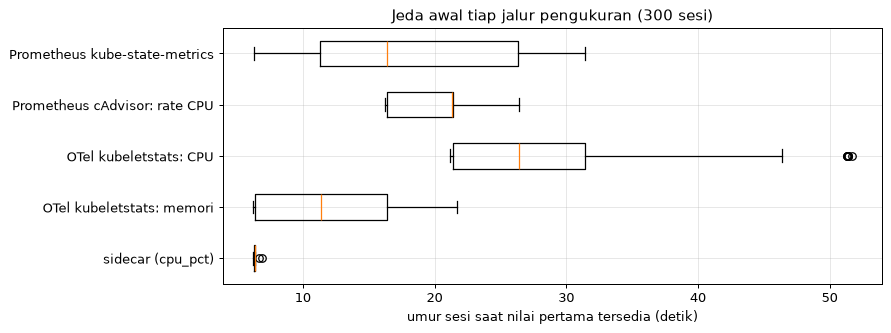

In [4]:
def first_age(col):
    return df[df[col].notna()].groupby("session_id").session_age_sec.min()


def change_period(col):
    # median detik antar perubahan nilai, hanya sesi yang nilainya memang berubah-ubah
    out = []
    for _, d in df.groupby("session_id"):
        d = d.sort_values("session_age_sec")
        s = d[col]
        if s.nunique() < 8:
            continue
        changed = d.session_age_sec[s.ne(s.shift()) & s.notna()]
        out.append(changed.diff().median())
    return float(np.nanmedian(out)) if out else np.nan


# (kolom untuk jeda awal, kolom gauge untuk periode pembaruan). Periode Prometheus diukur dari
# gauge memori: hasil rate() berubah di setiap langkah query walau sampel baru hanya tiap scrape.
PATHS = {
    "sidecar (cpu_pct)": ("cpu_pct", "cpu_pct"),
    "OTel kubeletstats: memori": ("otel_job_mem_ws_mb", "otel_job_mem_ws_mb"),
    "OTel kubeletstats: CPU": ("otel_job_cpu_cores", "otel_job_cpu_cores"),
    "Prometheus cAdvisor: rate CPU": ("prom_cpu_pct", "prom_mem_rss_mb"),
    "Prometheus kube-state-metrics": ("prom_cpu_request_cores", None),
}
lat = pd.DataFrame({name: first_age(col) for name, (col, _) in PATHS.items()})
table = lat.describe().T[["50%", "max"]].rename(columns={"50%": "nilai_pertama_median_s", "max": "nilai_pertama_maks_s"})
table["periode_pembaruan_s"] = [change_period(c) if c else np.nan for _, c in PATHS.values()]
display(table)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.boxplot([lat[c].dropna() for c in lat.columns], orientation="horizontal", tick_labels=lat.columns)
ax.set_xlabel("umur sesi saat nilai pertama tersedia (detik)")
ax.set_title("Jeda awal tiap jalur pengukuran (300 sesi)")
plt.tight_layout(); plt.show()

## 3. Validasi silang tiga jalur pengukuran
CPU dan memori container `job` diukur oleh tiga jalur yang independen: **sidecar** (psutil di dalam
Pod), **Prometheus** (cAdvisor lewat kubelet), dan **OTel** (kubeletstats). Kalau ketiganya sepakat,
pengukuran di dataset bisa dipercaya. Angka per sesi dihitung setelah 60 detik pertama.

In [5]:
st = df[df.session_age_sec > PROM_WARMUP_SEC]
cmp = st.groupby("session_id").agg(
    label=("label", "first"), job_type=("job_type", "first"),
    cpu_sidecar=("cpu_pct", lambda x: x.mean() / 100), cpu_prom=("prom_cpu_cores", "mean"),
    cpu_otel=("otel_job_cpu_cores", "mean"),
    rss_sidecar=("mem_rss_mb", "median"), ws_prom=("prom_mem_rss_mb", "median"),
    ws_otel=("otel_job_mem_ws_mb", "median"), rss_otel=("otel_job_mem_rss_mb", "median"))


def agreement(a, b):
    x, y = cmp[a], cmp[b]
    ok = x.notna() & y.notna()
    return {"n_sesi": int(ok.sum()), "korelasi": x[ok].corr(y[ok]),
            "rasio_median_b/a": (y[ok] / x[ok].where(x[ok].abs() > 1e-3)).median(),
            "selisih_abs_median": (y[ok] - x[ok]).abs().median()}


pairs = {"CPU: sidecar vs Prometheus (core)": ("cpu_sidecar", "cpu_prom"),
         "CPU: sidecar vs OTel (core)": ("cpu_sidecar", "cpu_otel"),
         "CPU: Prometheus vs OTel (core)": ("cpu_prom", "cpu_otel"),
         "Memori: working set Prometheus vs OTel (MB)": ("ws_prom", "ws_otel"),
         "Memori: RSS sidecar vs working set Prometheus (MB)": ("rss_sidecar", "ws_prom"),
         "Memori: RSS sidecar vs RSS OTel (MB)": ("rss_sidecar", "rss_otel")}
display(pd.DataFrame({name: agreement(a, b) for name, (a, b) in pairs.items()}).T)

,n_sesi,korelasi,rasio_median_b/a,selisih_abs_median
CPU: sidecar vs Prometheus (core),300.000,0.999,0.994,0.008
CPU: sidecar vs OTel (core),300.000,0.999,1.000,0.002
CPU: Prometheus vs OTel (core),300.000,1.000,1.001,0.009
Memori: working set Prometheus vs OTel (MB),300.000,0.999,1.000,0.000
Memori: RSS sidecar vs working set Prometheus (MB),300.000,0.995,0.729,292.794
Memori: RSS sidecar vs RSS OTel (MB),300.000,0.992,0.640,412.473


**Kenapa RSS sidecar lebih besar?** Sidecar menjumlahkan `memory_info().rss` semua proses job
(psutil). Nilai itu = memori anonim + halaman file/shared yang di-*map* (library Python, PyTorch,
CUDA). RSS versi cgroup (OTel `container_memory_rss`) hanya memori anonim. Jika penjelasan ini benar,
selisih absolutnya harus besar pada skenario yang memuat PyTorch dan kecil pada
`benign_eda_notebook`, satu-satunya skenario yang tidak memuat PyTorch.

In [6]:
ratio = pd.DataFrame({
    "rss_sidecar_mb": cmp.rss_sidecar.groupby(cmp.job_type).median(),
    "rss_otel_mb": cmp.rss_otel.groupby(cmp.job_type).median(),
    "selisih_mb": (cmp.rss_sidecar - cmp.rss_otel).groupby(cmp.job_type).median(),
    "rss_otel / rss_sidecar": (cmp.rss_otel / cmp.rss_sidecar).groupby(cmp.job_type).median(),
}).sort_values("selisih_mb")
display(ratio)

,rss_sidecar_mb,rss_otel_mb,selisih_mb,rss_otel / rss_sidecar
job_type,,,,
benign_eda_notebook,111.691,83.379,28.217,0.746
misuse_idle_hoarding,661.672,327.199,334.473,0.495
misuse_zombie_job,662.629,327.115,335.567,0.494
misuse_disguised_pattern,811.309,468.035,343.278,0.577
misuse_synthetic_load,811.578,467.986,343.590,0.577
misuse_overprovisioning,834.287,488.395,345.834,0.585
misuse_quota_exceed,823.779,477.422,346.365,0.580
misuse_idle_session,886.520,530.715,355.766,0.599
misuse_concurrent_sessions,969.785,608.609,361.176,0.628


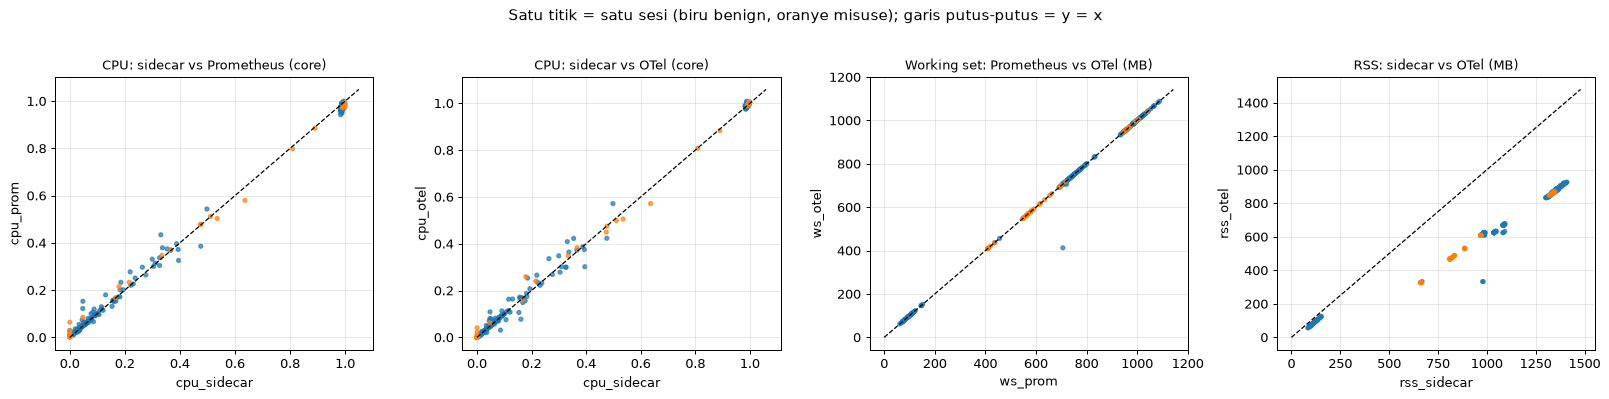

titik terjauh dari y = x pada working set: benign_interactive_gpu_notebook_0243 (706 vs 413 MB)


,session_age_sec,mem_rss_mb,prom_mem_rss_mb,otel_job_mem_ws_mb
10992,6.400,669.031,12.508,NaN
10995,21.400,669.047,412.926,412.926
10998,36.400,669.047,412.684,412.684
11001,51.400,669.055,412.691,412.684
11004,66.400,669.055,412.691,412.691
11007,81.400,980.977,706.465,412.691
11010,96.400,981.047,706.539,706.465
11013,111.400,980.754,706.535,706.539


-> sesi pendek yang memorinya naik di tengah sesi; OTel menyusul ~20 s kemudian, jadi median-nya berbeda.


In [7]:
color = cmp.label.map({"benign": "tab:blue", "misuse": "tab:orange"})
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
plots = [("cpu_sidecar", "cpu_prom", "CPU: sidecar vs Prometheus (core)"),
         ("cpu_sidecar", "cpu_otel", "CPU: sidecar vs OTel (core)"),
         ("ws_prom", "ws_otel", "Working set: Prometheus vs OTel (MB)"),
         ("rss_sidecar", "rss_otel", "RSS: sidecar vs OTel (MB)")]
for ax, (a, b, title) in zip(axes, plots):
    ax.scatter(cmp[a], cmp[b], s=10, c=color, alpha=0.7)
    hi = np.nanmax([cmp[a].max(), cmp[b].max()]) * 1.05
    ax.plot([0, hi], [0, hi], "k--", lw=1)
    ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(title, fontsize=10)
plt.suptitle("Satu titik = satu sesi (biru benign, oranye misuse); garis putus-putus = y = x", y=1.02)
plt.tight_layout(); plt.show()

odd = (cmp.ws_otel / cmp.ws_prom).idxmin()
print(f"titik terjauh dari y = x pada working set: {odd} ({cmp.loc[odd, 'ws_prom']:.0f} vs {cmp.loc[odd, 'ws_otel']:.0f} MB)")
d = df[df.session_id == odd].sort_values("session_age_sec")
display(d[["session_age_sec", "mem_rss_mb", "prom_mem_rss_mb", "otel_job_mem_ws_mb"]].iloc[::3])
print("-> sesi pendek yang memorinya naik di tengah sesi; OTel menyusul ~20 s kemudian, jadi median-nya berbeda.")

**Respons terhadap perubahan beban.** Tiga contoh sesi dengan beban yang berubah: R2 (aktif lalu
idle), S1 `disguised_pattern` (gelombang sinus), dan notebook interaktif (burst). Sidecar mengikuti
perubahan tiap 5 s, OTel tiap ±15 s, sedangkan `prom_cpu_cores` adalah rata-rata 1 menit sehingga
tertinggal dan lebih halus.

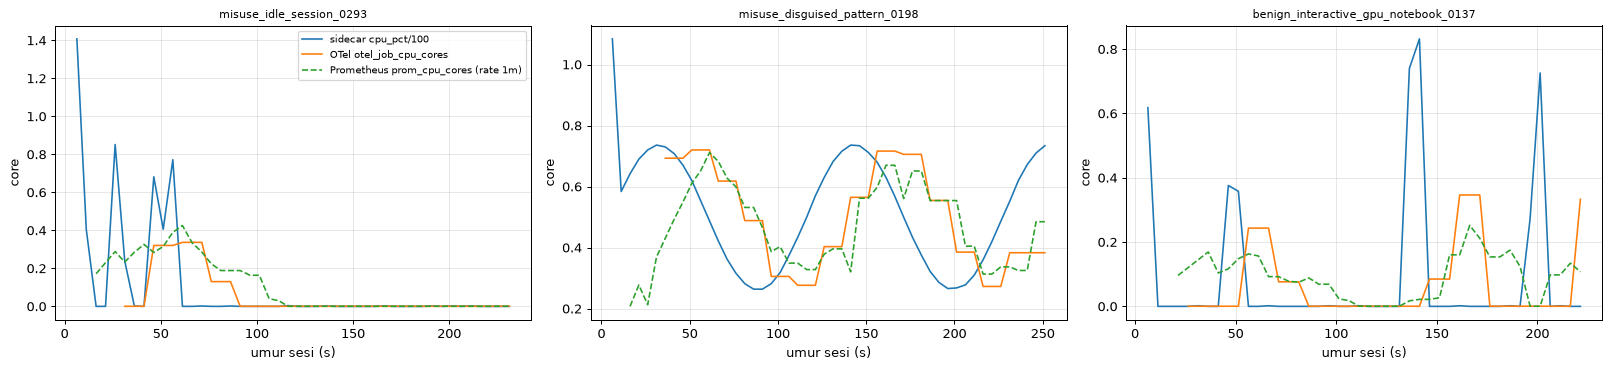

In [8]:
def pick(job):
    s = df[(df.job_type == job) & df.verified].groupby("session_id").session_age_sec.max()
    return (s - s.median()).abs().idxmin()


examples = [pick("misuse_idle_session"), pick("misuse_disguised_pattern"), pick("benign_interactive_gpu_notebook")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, sid in zip(axes, examples):
    d = df[df.session_id == sid].sort_values("session_age_sec")
    ax.plot(d.session_age_sec, d.cpu_pct / 100, label="sidecar cpu_pct/100", lw=1.3)
    ax.plot(d.session_age_sec, d.otel_job_cpu_cores, label="OTel otel_job_cpu_cores", lw=1.3)
    ax.plot(d.session_age_sec, d.prom_cpu_cores, label="Prometheus prom_cpu_cores (rate 1m)", lw=1.3, ls="--")
    ax.set_title(sid, fontsize=9); ax.set_xlabel("umur sesi (s)"); ax.set_ylabel("core")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Seberapa besar jeda OTel dan Prometheus?** Untuk sesi yang bebannya berubah-ubah, kolom OTel dan
Prometheus digeser mundur 0–60 detik lalu dikorelasikan dengan `cpu_pct` sidecar per baris.
Pergeseran dengan korelasi tertinggi = jeda jalur itu. Jeda ini datang dari rantai
cAdvisor/kubelet (±10–15 s) + interval scrape collector (15 s) + interval scrape Prometheus, dan
untuk `prom_cpu_cores` ditambah jendela `rate()` 1 menit.

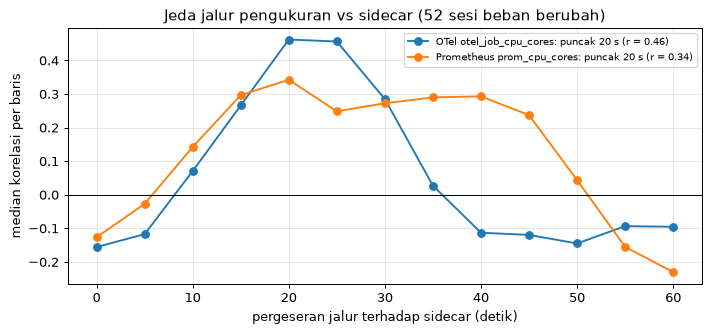

In [9]:
INTERVAL = float(plan["args"]["interval_sec"])
LAGS = np.arange(0, 13)
curves = {"OTel otel_job_cpu_cores": [], "Prometheus prom_cpu_cores": []}
for sid, d in st.groupby("session_id"):
    d = d.sort_values("session_age_sec")
    if d.cpu_pct.std() < 5 or len(d) < 20:
        continue
    for name, col in zip(curves, ["otel_job_cpu_cores", "prom_cpu_cores"]):
        curves[name].append([d.cpu_pct.corr(d[col].shift(-k)) for k in LAGS])

fig, ax = plt.subplots(figsize=(8, 3.8))
for name, rows in curves.items():
    med = np.nanmedian(np.array(rows), axis=0)
    best = int(np.nanargmax(med))
    ax.plot(LAGS * INTERVAL, med, marker="o", label=f"{name}: puncak {LAGS[best] * INTERVAL:.0f} s (r = {med[best]:.2f})")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("pergeseran jalur terhadap sidecar (detik)"); ax.set_ylabel("median korelasi per baris")
ax.set_title(f"Jeda jalur pengukuran vs sidecar ({len(curves['OTel otel_job_cpu_cores'])} sesi beban berubah)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Sinyal baru dari OTel per skenario
Yang tidak ada di dataset utama: **pemakaian filesystem** container, **page fault**, penghitung
**network** versi kubelet, dan pemakaian resource **sidecar telemetri** (biaya pengukuran).
Laju dihitung dari selisih penghitung kumulatif setelah `OTEL_WARMUP_SEC`.

In [10]:
def slope(d, col):
    s = d[["session_age_sec", col]].dropna()
    if len(s) < 2:
        return np.nan
    dt = s.session_age_sec.iloc[-1] - s.session_age_sec.iloc[0]
    return (s[col].iloc[-1] - s[col].iloc[0]) / dt if dt > 0 else np.nan


def supporting_features(data):
    rows = []
    for sid, d in data.groupby("session_id", sort=False):
        d = d.sort_values("session_age_sec")
        w = d[d.session_age_sec > OTEL_WARMUP_SEC]
        w = w if len(w) >= 3 else d
        rows.append({
            "session_id": sid, "label": d.label.iloc[0], "job_type": d.job_type.iloc[0],
            "scenario_code": d.scenario_code.iloc[0], "verified": d.verified.iloc[0],
            "start": d.timestamp.iloc[0],
            # --- OTel, level Pod/container ---
            "otel_cpu_cores": w.otel_job_cpu_cores.mean(),
            "otel_mem_ws_mb": w.otel_job_mem_ws_mb.median(),
            "otel_mem_rss_mb": w.otel_job_mem_rss_mb.median(),
            "fs_usage_max_mb": d.otel_job_fs_usage_mb.max(),
            "fs_growth_mbps": slope(w, "otel_job_fs_usage_mb"),
            "page_fault_per_s": slope(w, "otel_job_page_faults"),
            "major_faults_total": d.otel_job_major_page_faults.max(),
            "net_rx_kb": d.otel_pod_net_rx_kb.max(), "net_tx_kb": d.otel_pod_net_tx_kb.max(),
            "sidecar_cpu_mcores": 1000 * w.otel_sidecar_cpu_cores.mean(),
            "sidecar_mem_mb": w.otel_sidecar_mem_ws_mb.median(),
            # --- level host ---
            "pod_cpu_cores": w.otel_pod_cpu_cores.mean(),
            "host_cpu_busy": w.host_cpu_busy_cores.mean(),
            "host_bg_cpu": (w.host_cpu_busy_cores - w.otel_pod_cpu_cores).mean(),
            "host_user": w.host_cpu_user_cores.mean(), "host_system": w.host_cpu_system_cores.mean(),
            "host_softirq": w.host_cpu_softirq_cores.mean(),
            "host_iowait": w.host_cpu_iowait_cores.mean(), "host_load1": w.host_load1.mean(),
            "host_mem_used_mb": w.host_mem_used_mb.mean(),
            "host_disk_read_mbps": w.host_disk_read_mbps.mean(),
            "host_disk_write_mbps": w.host_disk_write_mbps.mean(),
            "ig_ops_per_s": w.ig_blockio_ops_per_s.mean(),
            "ig_lat_p50_us": w.ig_blockio_lat_p50_us.median(), "ig_lat_p99_us": w.ig_blockio_lat_p99_us.median(),
            # --- pembanding dari dataset utama ---
            "cpu_pct_mean": w.cpu_pct.mean(), "mem_rss_median": w.mem_rss_mb.median(),
            "gpu_util_mean": w.gpu_util_pct.mean(), "vram_max_mb": d.gpu_mem_used_mb_device.max(),
            "io_read_mbps": slope(w, "io_read_mb"), "io_write_mbps": slope(w, "io_write_mb"),
            "last_activity_max": d.last_activity_age_sec.max(),
        })
    return pd.DataFrame(rows).set_index("session_id")


sf = supporting_features(df)
POD_FEATURES = ["otel_cpu_cores", "otel_mem_ws_mb", "otel_mem_rss_mb", "fs_usage_max_mb", "fs_growth_mbps",
                "page_fault_per_s", "major_faults_total", "net_rx_kb", "net_tx_kb", "sidecar_cpu_mcores", "sidecar_mem_mb"]
HOST_FEATURES = ["host_cpu_busy", "host_bg_cpu", "host_iowait", "host_load1", "host_mem_used_mb",
                 "host_disk_read_mbps", "host_disk_write_mbps", "ig_ops_per_s", "ig_lat_p50_us", "ig_lat_p99_us"]
MAIN_FEATURES = ["cpu_pct_mean", "mem_rss_median", "gpu_util_mean", "vram_max_mb", "io_read_mbps",
                 "io_write_mbps", "last_activity_max"]
display(sf.groupby(["scenario_code", "job_type"])[
    ["fs_usage_max_mb", "page_fault_per_s", "major_faults_total", "net_rx_kb", "net_tx_kb",
     "sidecar_cpu_mcores", "sidecar_mem_mb"]].median())

fs_usage_max_mb  page_fault_per_s  major_faults_total  net_rx_kb  net_tx_kb  sidecar_cpu_mcores  sidecar_mem_mb
scenario_code job_type                                                                                                                                        
BENIGN        benign_batch_inference                     1.273            46.955              65.000      0.729      0.846               3.620          28.496
              benign_cnn_training                        9.215             0.251              78.000      0.729      0.914               3.950          30.312
              benign_data_pipeline_training            219.910           189.837              67.000      0.729      0.914               4.046          30.344
              benign_eda_notebook                        0.480             0.262              31.000      0.729      0.846               3.605          28.254
              benign_interactive_gpu_notebook            1.004             9.374              42.000      0.729      0.846               3.670          28.461
P5            misuse_gpu_monopolization                  1.387             0.077              48.000      0.729      0.914               3.703          29.332
R1            misuse_idle_hoarding                       1.102             0.021              18.000      0.729      0.846               3.588          28.324
R2            misuse_idle_session                        1.023             0.086              65.000      0.729      0.846               3.938          28.258
R3            misuse_quota_exceed                        0.930             0.000              28.500      0.729      0.846               3.655          28.283
R4            misuse_overprovisioning                    0.934           171.534               2.500      0.729      0.880               3.596          28.246
R5            misuse_zombie_job                          1.326             0.087               0.000      0.729      0.812               3.652          28.250
R6            misuse_concurrent_sessions                 0.930             0.064              25.000      0.729      0.846               3.818          28.820
R7            misuse_inefficient_gpu                     1.223             0.113              59.500      0.729      0.846               3.651          29.273
S1            misuse_disguised_pattern                   1.426             0.005              28.000      0.729      0.846               3.610          28.258
              misuse_synthetic_load                      1.211             0.000              15.000      0.729      0.846               3.736          28.480

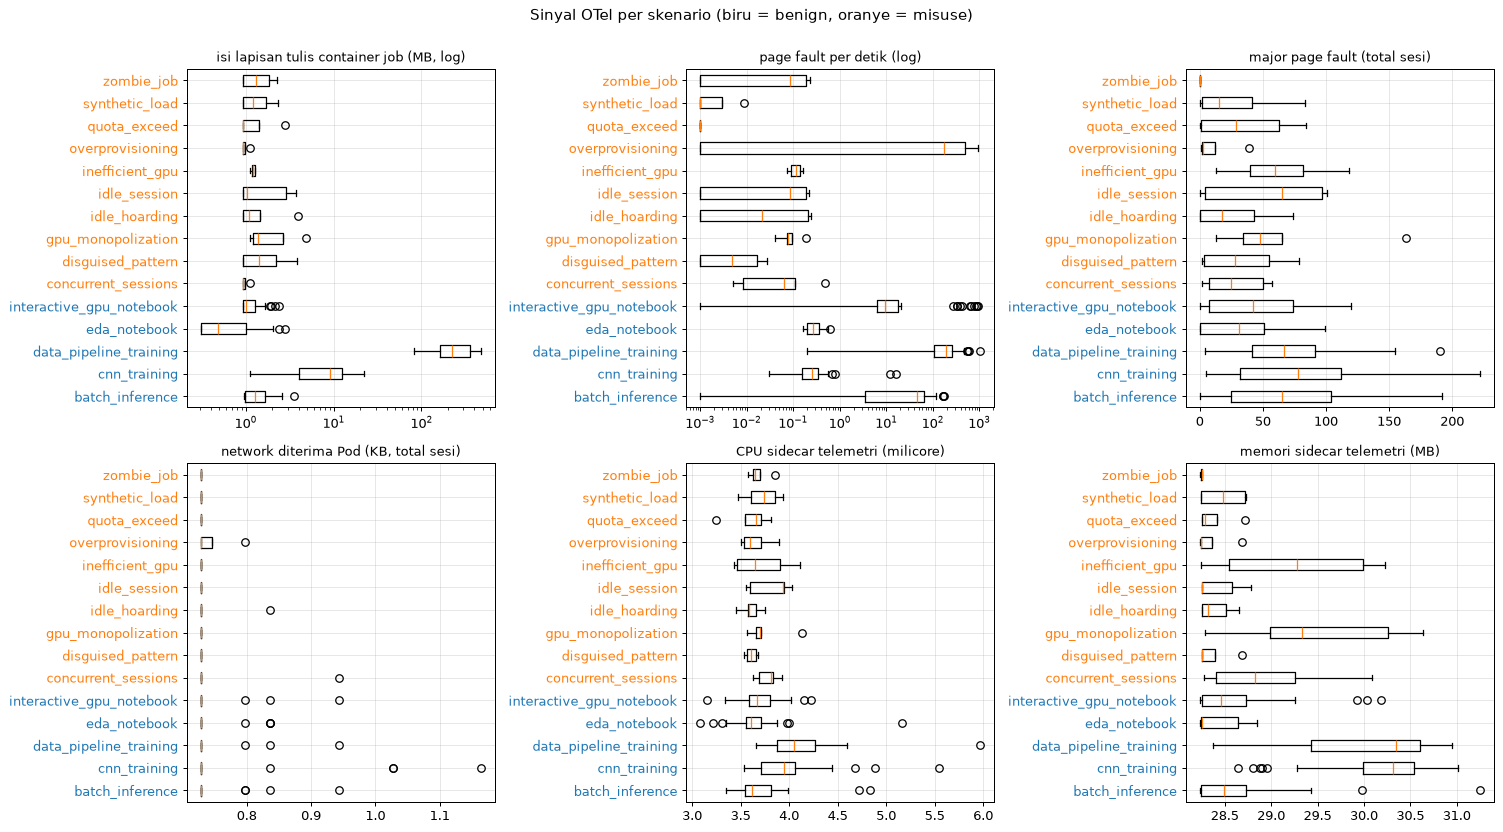

In [11]:
def boxes(features, title, ncols=3, logx=()):
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.6 * ncols, 4.6 * nrows), squeeze=False)
    for ax, (col, label) in zip(axes.flat, features):
        data = [sf.loc[sf.job_type == j, col].dropna().clip(lower=1e-3 if col in logx else None) for j in ORDER]
        ax.boxplot(data, orientation="horizontal", tick_labels=[SHORT[j] for j in ORDER])
        if col in logx:
            ax.set_xscale("log")
        ax.set_title(label, fontsize=10)
        for lbl in ax.get_yticklabels():
            lbl.set_color("tab:orange" if ("misuse_" + lbl.get_text()) in SHORT else "tab:blue")
    for ax in axes.flat[len(features):]:
        ax.axis("off")
    plt.suptitle(title, y=1.0); plt.tight_layout(); plt.show()


boxes([("fs_usage_max_mb", "isi lapisan tulis container job (MB, log)"),
       ("page_fault_per_s", "page fault per detik (log)"),
       ("major_faults_total", "major page fault (total sesi)"),
       ("net_rx_kb", "network diterima Pod (KB, total sesi)"),
       ("sidecar_cpu_mcores", "CPU sidecar telemetri (milicore)"),
       ("sidecar_mem_mb", "memori sidecar telemetri (MB)")],
      "Sinyal OTel per skenario (biru = benign, oranye = misuse)", logx=("fs_usage_max_mb", "page_fault_per_s"))

**Overhead sidecar.** Sidecar telemetri berjalan di Pod yang sama dengan job. Perbandingannya dengan
pemakaian job menunjukkan apakah pengukuran itu sendiri mengganggu beban yang diukur.

In [12]:
over = sf[["sidecar_cpu_mcores", "sidecar_mem_mb"]].describe().T[["mean", "50%", "min", "max"]]
display(over)
share = (sf.sidecar_cpu_mcores / 1000) / sf.pod_cpu_cores.where(sf.pod_cpu_cores > 0.05)
print(f"CPU sidecar rata-rata {sf.sidecar_cpu_mcores.mean():.1f} milicore "
      f"(= {sf.sidecar_cpu_mcores.mean() / 10:.2f}% satu core), memori median {sf.sidecar_mem_mb.median():.0f} MB.")
print(f"Porsi CPU sidecar terhadap CPU Pod pada sesi yang CPU-nya > 0,05 core: median {100 * share.median():.2f}%")
print("Variasi antar skenario (median milicore):",
      sf.groupby("job_type").sidecar_cpu_mcores.median().round(2).agg(["min", "max"]).to_dict())

,mean,50%,min,max
sidecar_cpu_mcores,3.802,3.718,3.084,5.972
sidecar_mem_mb,29.077,28.684,28.230,31.250


CPU sidecar rata-rata 3.8 milicore (= 0.38% satu core), memori median 29 MB.
Porsi CPU sidecar terhadap CPU Pod pada sesi yang CPU-nya > 0,05 core: median 0.60%
Variasi antar skenario (median milicore): {'min': 3.59, 'max': 4.05}


## 5. Apakah metrik supporting menambah informasi untuk deteksi?
- **AUC** tiap fitur untuk membedakan benign vs misuse pada sesi *verified* (0,5 = acak).
- **Korelasi** fitur supporting dengan fitur dataset utama: |r| mendekati 1 berarti fitur itu
  mengulang informasi yang sudah ada.

Fitur level host tidak menggambarkan perilaku sesi secara langsung: nilainya ikut naik hanya karena
beban job termasuk di dalam beban host.

,kelompok,AUC,keterpisahan
page_fault_per_s,OTel Pod,0.118,0.882
last_activity_max,dataset utama,0.735,0.735
io_read_mbps,dataset utama,0.291,0.709
ig_lat_p99_us,host,0.297,0.703
host_disk_read_mbps,host,0.310,0.690
ig_ops_per_s,host,0.317,0.683
mem_rss_median,dataset utama,0.318,0.682
otel_mem_rss_mb,OTel Pod,0.320,0.680
otel_mem_ws_mb,OTel Pod,0.331,0.669
host_disk_write_mbps,host,0.334,0.666


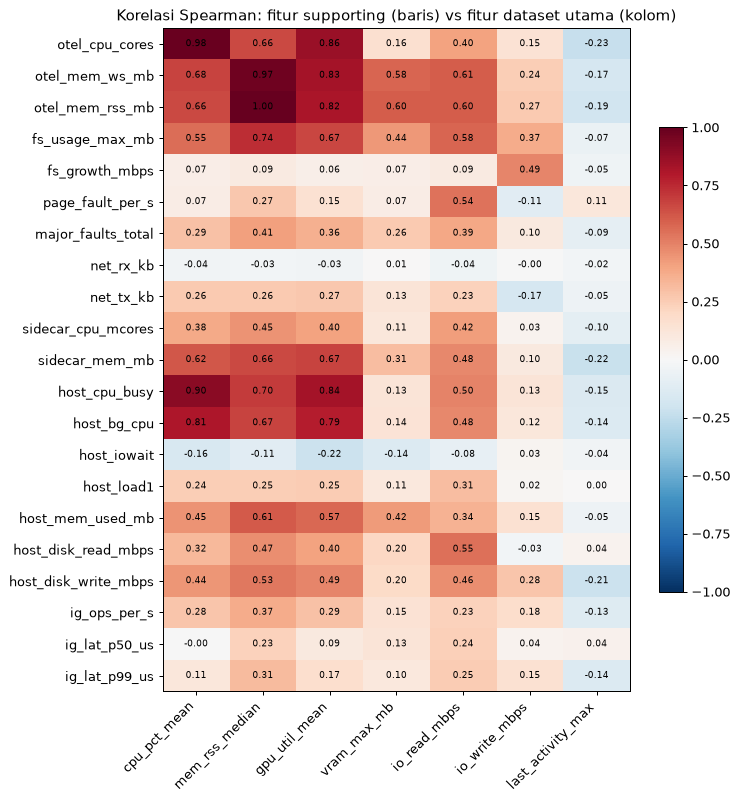

fitur supporting yang paling tidak redundan (|r| maksimum terhadap fitur utama):
net_rx_kb            0.040
host_iowait          0.220
ig_lat_p50_us        0.240
net_tx_kb            0.270
host_load1           0.310
ig_lat_p99_us        0.310
ig_ops_per_s         0.370
major_faults_total   0.410


In [13]:
sv = sf[sf.verified]
y = (sv.label == "misuse").astype(int)
rows = {}
for c in POD_FEATURES + HOST_FEATURES + MAIN_FEATURES:
    x = sv[c].fillna(sv[c].median())
    if x.nunique() > 1:
        a = roc_auc_score(y, x)
        rows[c] = {"kelompok": "OTel Pod" if c in POD_FEATURES else "host" if c in HOST_FEATURES else "dataset utama",
                   "AUC": a, "keterpisahan": max(a, 1 - a)}
auc = pd.DataFrame(rows).T.astype({"AUC": float, "keterpisahan": float}).sort_values("keterpisahan", ascending=False)
display(auc)

corr = sv[POD_FEATURES + HOST_FEATURES + MAIN_FEATURES].corr(method="spearman").loc[POD_FEATURES + HOST_FEATURES, MAIN_FEATURES]
fig, ax = plt.subplots(figsize=(8.5, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(MAIN_FEATURES)), MAIN_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title("Korelasi Spearman: fitur supporting (baris) vs fitur dataset utama (kolom)")
ax.grid(False); plt.tight_layout(); plt.show()
best = corr.abs().max(axis=1)
print("fitur supporting yang paling tidak redundan (|r| maksimum terhadap fitur utama):")
print(best.sort_values().head(8).round(2).to_string())

**Cara membaca.** AUC < 0,5 berarti nilai fitur lebih tinggi pada benign. AUC per sesi di sini
terutama mencerminkan *skenario mana* yang ada di tiap kelas, karena tiap skenario punya pola yang
khas. Sebelum fitur baru dipakai, periksa skenario apa yang mendorong AUC-nya (tabel di bawah dan
bagian 4) dan uji dengan validasi per skenario (*leave-one-scenario-out*), bukan hanya per baris acak.

In [14]:
pf = sv.groupby(["label", "job_type"]).page_fault_per_s.median().sort_values(ascending=False)
print("median page fault per detik per skenario (sesi verified):")
print(pf.round(2).to_string())

median page fault per detik per skenario (sesi verified):
label   job_type                       
benign  benign_data_pipeline_training     184.660
misuse  misuse_overprovisioning           171.530
benign  benign_batch_inference             46.950
        benign_interactive_gpu_notebook     9.370
        benign_eda_notebook                 0.260
        benign_cnn_training                 0.240
misuse  misuse_inefficient_gpu              0.110
        misuse_zombie_job                   0.090
        misuse_idle_session                 0.090
        misuse_gpu_monopolization           0.080
        misuse_concurrent_sessions          0.060
        misuse_idle_hoarding                0.020
        misuse_disguised_pattern            0.000
        misuse_quota_exceed                 0.000
        misuse_synthetic_load               0.000


## 6. Konteks host selama run
`host_bg_cpu` = CPU host yang sibuk dikurangi CPU Pod sesi = beban latar (cluster, monitoring,
dan tools supporting itu sendiri). Kalau beban latar dan memori host stabil sepanjang run, kondisi
pengukuran antar sesi setara.

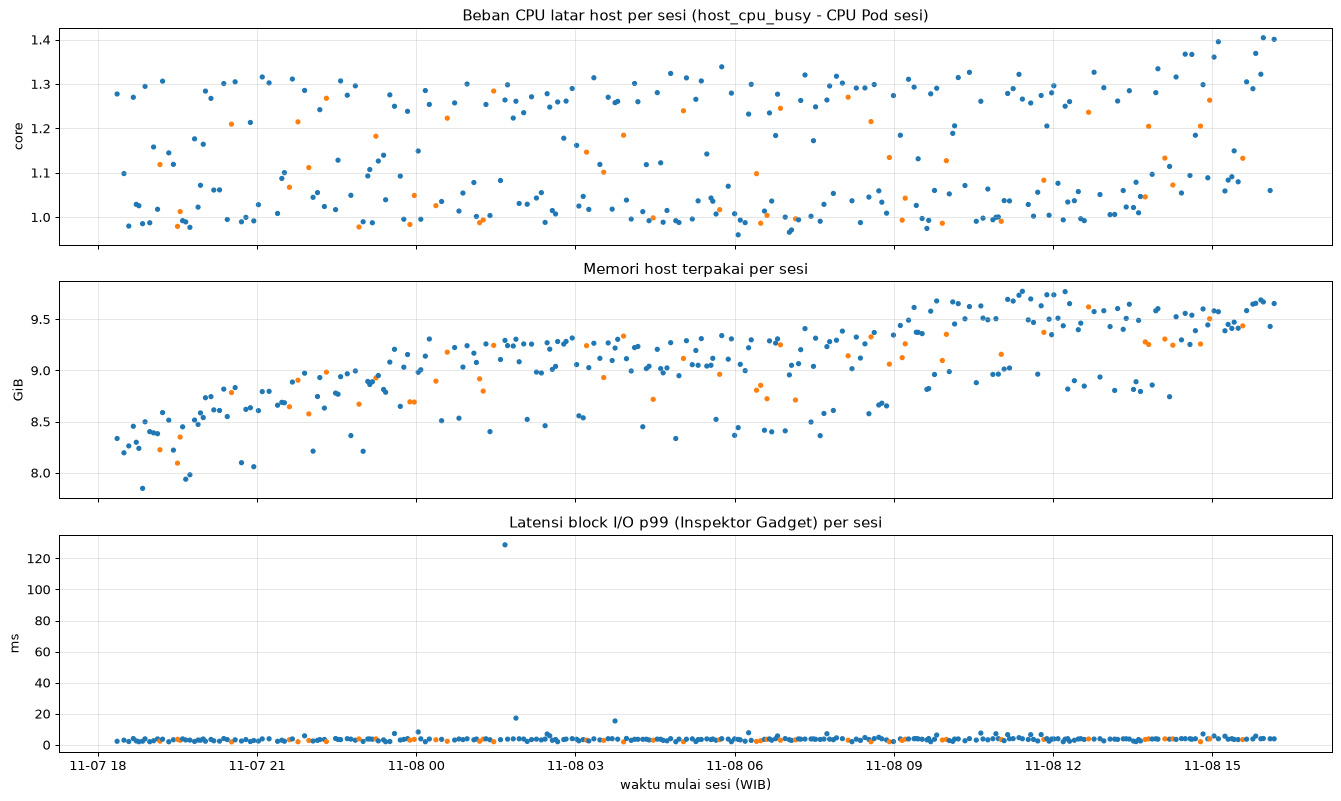

,rata2,std,min,maks,tren_per_jam
host_bg_cpu,1.136,0.125,0.960,1.404,0.002
host_mem_used_mb,"9,258.389",422.252,"8,036.537","10,008.470",47.211
host_load1,2.037,1.360,0.234,7.903,-0.004
host_iowait,0.018,0.009,0.013,0.144,-0.000
ig_ops_per_s,66.802,16.279,46.953,200.933,0.639
ig_lat_p99_us,"4,021.157","7,371.426","1,907.512","128,734.283",-5.139


In [15]:
t = sf.sort_values("start")
wib = t.start.dt.tz_convert("Asia/Jakarta")
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
c = t.label.map({"benign": "tab:blue", "misuse": "tab:orange"})
axes[0].scatter(wib, t.host_bg_cpu, s=10, c=c); axes[0].set_ylabel("core")
axes[0].set_title("Beban CPU latar host per sesi (host_cpu_busy - CPU Pod sesi)")
axes[1].scatter(wib, t.host_mem_used_mb / 1024, s=10, c=c); axes[1].set_ylabel("GiB")
axes[1].set_title("Memori host terpakai per sesi")
axes[2].scatter(wib, t.ig_lat_p99_us / 1000, s=10, c=c); axes[2].set_ylabel("ms")
axes[2].set_title("Latensi block I/O p99 (Inspektor Gadget) per sesi"); axes[2].set_xlabel("waktu mulai sesi (WIB)")
plt.tight_layout(); plt.show()

hours = (t.start - t.start.iloc[0]).dt.total_seconds() / 3600
stab = pd.DataFrame({c: {"rata2": t[c].mean(), "std": t[c].std(), "min": t[c].min(), "maks": t[c].max(),
                         "tren_per_jam": np.polyfit(hours[t[c].notna()], t[c].dropna(), 1)[0]}
                     for c in ["host_bg_cpu", "host_mem_used_mb", "host_load1", "host_iowait", "ig_ops_per_s", "ig_lat_p99_us"]}).T
display(stab)

**Kenapa beban latar terbagi dua kelompok (±1,0 dan ±1,3 core)?** Sesi dikelompokkan menurut jenis
bebannya, lalu CPU host dipecah per state. Jika selisih antar kelompok muncul di `softirq`, berarti
kernel ikut bekerja lebih keras saat job sibuk, dan kerja itu tidak tercatat di cgroup Pod mana pun.

In [16]:
def load_type(r):
    if pd.isna(r.gpu_util_mean):
        return "5 data GPU kosong"
    if r.gpu_util_mean >= 30:
        return "3 GPU sibuk"
    if r.pod_cpu_cores > 0.5:
        return "2 CPU sibuk, GPU idle"
    if r.pod_cpu_cores < 0.05 and r.gpu_util_mean < 5:
        return "1 idle"
    return "4 lainnya"


sf["jenis_beban"] = sf.apply(load_type, axis=1)
states = sf.groupby("jenis_beban")[["pod_cpu_cores", "host_cpu_busy", "host_bg_cpu",
                                     "host_user", "host_system", "host_softirq"]].mean()
states.insert(0, "n_sesi", sf.jenis_beban.value_counts())
display(states)
idle = states.loc["1 idle"]
print("kenaikan dibanding sesi idle (core):")
print((states[["host_bg_cpu", "host_softirq"]] - idle[["host_bg_cpu", "host_softirq"]]).round(3).to_string())

,n_sesi,pod_cpu_cores,host_cpu_busy,host_bg_cpu,host_user,host_system,host_softirq
jenis_beban,,,,,,,
1 idle,60,0.032,1.049,1.015,0.431,0.447,0.173
"2 CPU sibuk, GPU idle",5,0.915,2.092,1.177,1.279,0.504,0.313
3 GPU sibuk,122,0.949,2.214,1.269,1.077,0.812,0.328
4 lainnya,113,0.133,1.191,1.056,0.528,0.474,0.191


kenaikan dibanding sesi idle (core):
                       host_bg_cpu  host_softirq
jenis_beban                                     
1 idle                       0.000         0.000
2 CPU sibuk, GPU idle        0.162         0.141
3 GPU sibuk                  0.253         0.155
4 lainnya                    0.041         0.018


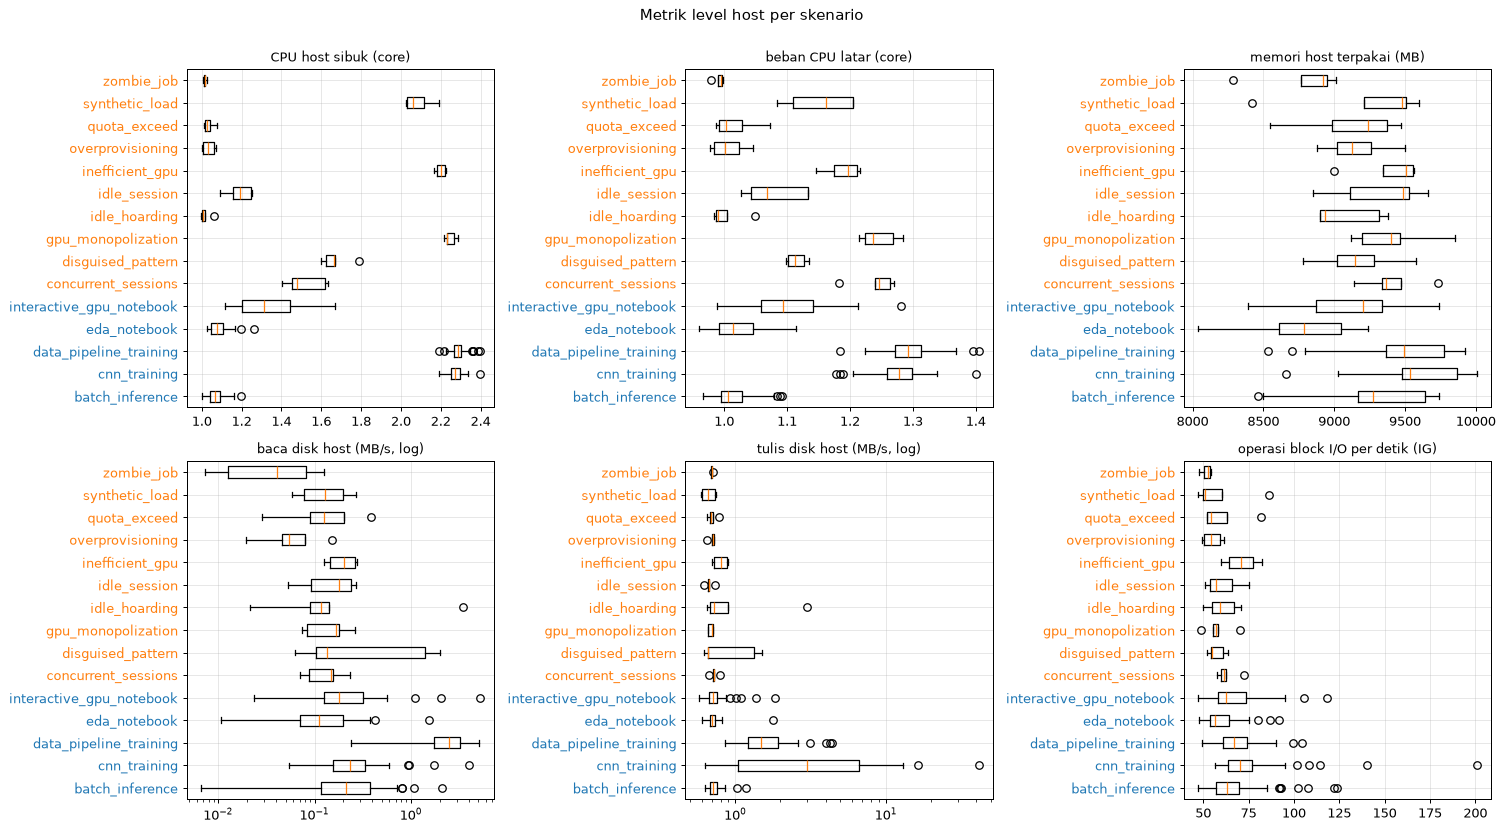

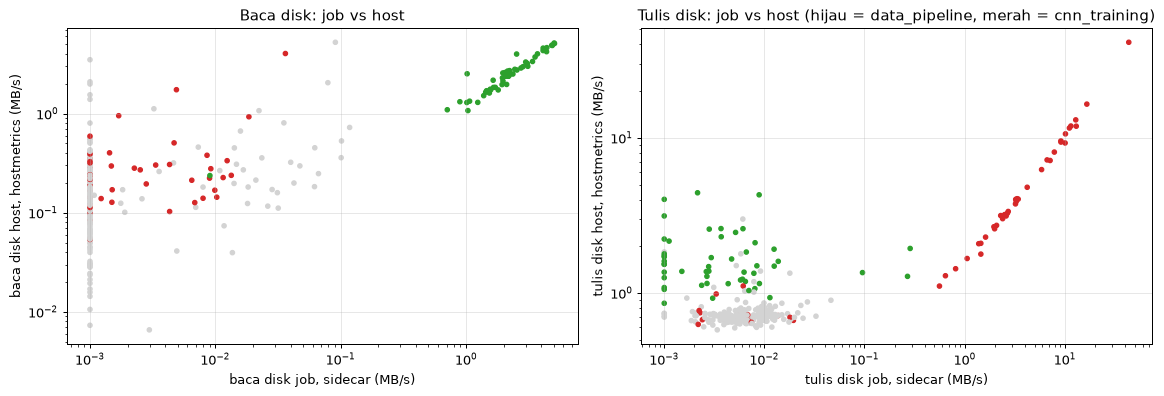

korelasi Spearman baca disk job vs host: 0.615 | tulis: 0.249
tulis disk host saat job tidak menulis (io_write < 0,05 MB/s): median 0.72 MB/s = tulis latar (Prometheus, Loki, dll.)


In [17]:
boxes([("host_cpu_busy", "CPU host sibuk (core)"), ("host_bg_cpu", "beban CPU latar (core)"),
       ("host_mem_used_mb", "memori host terpakai (MB)"),
       ("host_disk_read_mbps", "baca disk host (MB/s, log)"), ("host_disk_write_mbps", "tulis disk host (MB/s, log)"),
       ("ig_ops_per_s", "operasi block I/O per detik (IG)")],
      "Metrik level host per skenario", logx=("host_disk_read_mbps", "host_disk_write_mbps"))

# Konsistensi antar tool: I/O job (cgroup io.stat, sidecar) vs disk host (hostmetrics)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
c = sf.job_type.map(lambda j: "tab:green" if j == "benign_data_pipeline_training" else
                    "tab:red" if j == "benign_cnn_training" else "lightgrey")
axes[0].scatter(sf.io_read_mbps.clip(lower=1e-3), sf.host_disk_read_mbps.clip(lower=1e-3), s=12, c=c)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("baca disk job, sidecar (MB/s)"); axes[0].set_ylabel("baca disk host, hostmetrics (MB/s)")
axes[0].set_title("Baca disk: job vs host")
axes[1].scatter(sf.io_write_mbps.clip(lower=1e-3), sf.host_disk_write_mbps.clip(lower=1e-3), s=12, c=c)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("tulis disk job, sidecar (MB/s)"); axes[1].set_ylabel("tulis disk host, hostmetrics (MB/s)")
axes[1].set_title("Tulis disk: job vs host (hijau = data_pipeline, merah = cnn_training)")
plt.tight_layout(); plt.show()
print("korelasi Spearman baca disk job vs host:", round(sf.io_read_mbps.corr(sf.host_disk_read_mbps, method="spearman"), 3),
      "| tulis:", round(sf.io_write_mbps.corr(sf.host_disk_write_mbps, method="spearman"), 3))
print("tulis disk host saat job tidak menulis (io_write < 0,05 MB/s): median",
      round(sf.loc[sf.io_write_mbps < 0.05, "host_disk_write_mbps"].median(), 2), "MB/s = tulis latar (Prometheus, Loki, dll.)")

## 7. NetObserv: flow jaringan
NetObserv (agen eBPF) mencatat flow IP dan mengelompokkannya per namespace/workload. Tabel di bawah
adalah jumlah flow selama seluruh run per pasangan namespace (nama kosong = di luar cluster atau
jaringan host).

pasangan namespace yang punya flow selama run: 58; total flow 10,521,054
flow yang melibatkan namespace 'testbed-jobs': 0 (0 pasangan)


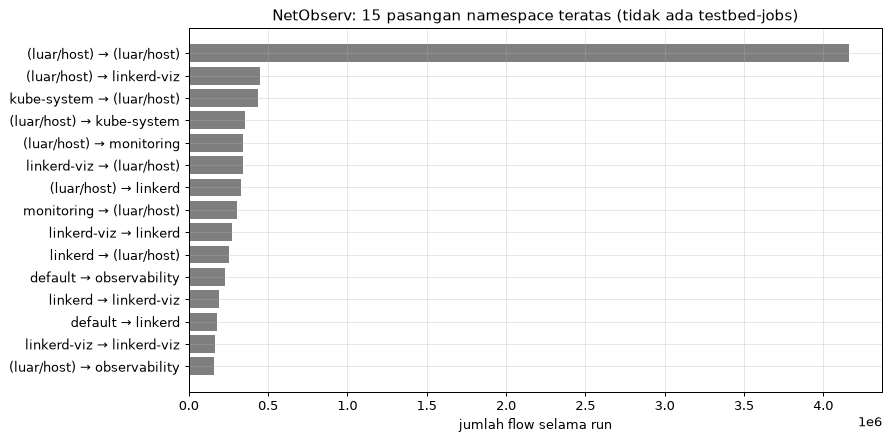


network Pod sesi menurut kubelet (OTel), total per sesi:


,mean,50%,min,max
net_rx_kb,0.739,0.729,0.729,1.164
net_tx_kb,0.855,0.846,0.777,1.174


prom_net_rx_mb (cAdvisor) rata-rata seluruh baris: 0.0031 KB/s


In [18]:
flows[["flows", "ingress_bytes"]] = flows[["flows", "ingress_bytes"]].apply(pd.to_numeric)
ns = plan["args"].get("namespace", "testbed-jobs")
involved = flows[(flows.src_namespace == ns) | (flows.dst_namespace == ns)]
print(f"pasangan namespace yang punya flow selama run: {len(flows)}; total flow {flows.flows.sum():,.0f}")
print(f"flow yang melibatkan namespace '{ns}': {involved.flows.sum():,.0f} ({len(involved)} pasangan)")

top = flows.head(15).copy()
top["pasangan"] = top.src_namespace.replace("", "(luar/host)") + " → " + top.dst_namespace.replace("", "(luar/host)")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top.pasangan[::-1], top.flows[::-1], color="tab:gray")
ax.set_xlabel("jumlah flow selama run"); ax.set_title("NetObserv: 15 pasangan namespace teratas (tidak ada testbed-jobs)")
plt.tight_layout(); plt.show()

print("\nnetwork Pod sesi menurut kubelet (OTel), total per sesi:")
display(sf[["net_rx_kb", "net_tx_kb"]].describe().T[["mean", "50%", "min", "max"]])
print("prom_net_rx_mb (cAdvisor) rata-rata seluruh baris:", f"{df.prom_net_rx_mb.mean() * 1024:.4f} KB/s")

## 8. Ringkasan
Angka di bawah berasal dari run `data-v3-20261107`. Kalau notebook dijalankan untuk run lain, baca
ulang angkanya dari keluaran sel.

**Apakah metrik supporting masuk dataset?** Tidak di `dataset.csv`. Sekarang tersedia di
`dataset_extended.csv`: 29 kolom tambahan, ke-300 sesi punya data, dan terisi 100% setelah 60 detik
pertama.

1. **OTel kubeletstats tidak menambah informasi CPU/memori.** CPU dan working set versi OTel identik
   dengan cAdvisor (korelasi 0,999–1,000, rasio median 1,000), karena keduanya membaca cgroup yang
   sama lewat kubelet. Sebaliknya, kesepakatan tiga jalur independen (sidecar, Prometheus, OTel)
   menjadi bukti bahwa pengukuran CPU/memori di dataset valid. RSS sidecar lebih besar dari RSS
   cgroup karena psutil ikut menghitung library yang di-*map*: selisihnya ratusan MB pada skenario
   PyTorch dan hanya puluhan MB pada `eda_notebook`. Ini beda definisi, bukan kesalahan ukur.
   I/O disk dari sidecar (fallback cgroup `io.stat`) juga selaras dengan disk host versi
   hostmetrics pada sesi yang benar-benar membaca (data_pipeline) atau menulis (cnn_training).
2. **Prometheus dan OTel tertinggal ±20 detik dari sidecar**, dan nilai CPU OTel pertama baru muncul
   ±26 detik setelah sesi mulai (paling lambat ±52 detik). Detektor yang membaca Prometheus (misalnya
   `daemon_scorer`) mewarisi jeda ini.
3. **Sinyal baru yang paling menjanjikan adalah laju page fault** (AUC 0,12, artinya benign jauh
   lebih tinggi; keterpisahan tertinggi di antara semua fitur yang diuji), disusul pemakaian
   filesystem container dan major page fault. Page fault tinggi datang dari skenario yang memproses
   data (data_pipeline, overprovisioning, batch_inference), jadi kemungkinan besar mencerminkan
   implementasi skenario. Uji dulu dengan validasi per skenario sebelum diklaim sebagai fitur deteksi.
4. **Network tidak berguna untuk dataset ini.** Tiap Pod sesi hanya menerima ±0,7 KB, dan NetObserv
   mencatat 0 flow untuk `testbed-jobs` dari ±10,5 juta flow di cluster, karena tidak ada skenario
   yang memakai jaringan. Kalau NetObserv mau dipakai di TA, perlu skenario yang memang berjaringan.
5. **Overhead sidecar kecil dan seragam:** ±3,8 milicore dan ±29 MB (median 0,6% CPU Pod), hampir
   sama di semua skenario, jadi sidecar tidak membocorkan label.
6. **Metrik host bukan fitur per sesi.** Nilainya ikut naik karena beban job itu sendiri (korelasi
   0,8–0,9 dengan CPU job) dan karena kerja kernel (softirq) yang bertambah saat job sibuk. Memori
   host juga naik perlahan sepanjang run (±47 MB/jam). Pakai hanya sebagai konteks kondisi cluster.
7. **Kondisi pengukuran stabil sepanjang 22 jam run:** beban latar 1,1 ± 0,1 core tanpa tren, dan
   latensi block I/O p99 ±4 ms dengan satu lonjakan 128 ms.

**Untuk run berikutnya:** jalankan `fetch_supporting_metrics.py` segera setelah run selesai, sebelum
`down-all.sh` atau sebelum retensi 10 hari Prometheus lewat.